In [1]:
# --- project bootstrap ---
# common/ holds the shared modules (geom_utils, mosaic_utils*).
import sys, pathlib
_common = str(pathlib.Path.cwd().parent / "common")
if _common not in sys.path:
    sys.path.insert(0, _common)
# -------------------------

In [2]:
!which python3
import lsst.daf.butler as dafButler
from lsst.summit.utils.utils import getCameraFromInstrumentName
import os
import numpy as np


from astropy.time import Time
from astropy.coordinates import EarthLocation, SkyCoord, AltAz 
from astropy import units as u
from astroquery.vizier import Vizier
import matplotlib.pyplot as plt
from astropy.time import Time, TimeDelta
from matplotlib.patches import Rectangle 
from skyfield.api import load
from lsst.summit.utils import ConsDbClient

import geom_utils as gu
vscode= True

if vscode == True:
    URL = "https://usdf-rsp.slac.stanford.edu/consdb" #for vscode 
    tk = os.environ["CONSDB_TOKEN"]  # set in .env (see README)
    cdb_client = ConsDbClient(URL,token=tk)
else:
    URL = "http://consdb-pq.consdb:8080/consdb"  
    os.environ["no_proxy"] += ",.consdb"
    cdb_client = ConsDbClient(URL,token=tk)

visit=None

# query_table = f"""
#         SELECT
#             visit_id AS visit_id,
#             physical_rotator_angle  AS rot_ang
#         FROM
#             cdb_lsstcam.visit1

# """ 
# rotation_df = cdb_client.query(query_table).to_pandas()
camera = getCameraFromInstrumentName("LSSTCam")
# print(dir(cdb_client))


/sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.1.0/bin/python3


        Use pytest instead. [astropy.tests.runner]
        Use pytest instead.
        Use pytest instead. [astropy.utils.decorators]
        Use pytest instead.


In [8]:
submarine =[]
submarine += [2025071800417, 2025071800421]
# submarine += list(range(2026092800876, 2026092800880+1))
submarine += [2026061400488, 2026061400489]  #, 2026031000208, 2026031200632, 2026042700129]
visit_list = submarine
# # 2026030600232,2026030600242,2026030600249,2026030600252,
# # 2026030600257,2025110800376,2026031000207,2026041100564,
# # 2026031200268,2026011500328,2025121600240,2026021600288,2025111600378,
# # 2026041900344,2025062000494,2025112500279,2026032500623,2026040100218, 2026050100070]

In [ ]:
from tqdm import tqdm
import gc
butler1 = dafButler.Butler("embargo", collections=["LSSTCam/runs/nightlyValidation", "LSSTCam/raw/all"], instrument="LSSTCam")  # type: ignore
butler2 = dafButler.Butler("main", collections=["LSSTCam/raw/all", "u/ataranto/general_outputs"], instrument="LSSTCam") # type: ignore

max_dist = 45
limit = 8
save_zpl = True  # Set to False if you do not want to write source_field<visit>.ZPL
arr = []
for visit in visit_list:
    lista=[]
    # visit+=1
    if visit > 2026100000000:
        butler=butler1
    else:
        butler=butler2
    rot_ang = np.nan
    try:
        query = f"""
            SELECT
                visit_id,
                physical_rotator_angle
            FROM
                cdb_lsstcam.visit1_quicklook
            WHERE
                visit_id = {visit}
        """
        rotation_df = cdb_client.query(query).to_pandas()
        if rotation_df.empty:
            raise ValueError(f"Nessun risultato per visit_id={visit}")
        rot_ang = rotation_df["physical_rotator_angle"].values[0]
    except Exception as e:
        print(e)
    print(rot_ang)
    gc.collect()
    if len(lista) > 30: break

    t = butler.get("raw.visitInfo", exposure=visit, detector=94).date.toAstropy()
    ra = butler.get("raw.visitInfo", exposure=visit, detector=94).boresightRaDec.getRa().asDegrees()
    dec = butler.get("raw.visitInfo", exposure=visit, detector=94).boresightRaDec.getDec().asDegrees()
    info = butler.get("raw.visitInfo", detector=94, exposure=visit)  # change exposure to visit for raw or post_isr
    st_time = str(info.date).split('"')[1]
    center = SkyCoord(ra=ra, dec=dec, unit=(u.deg, u.deg), frame='icrs')
    print(f"Processing visit {visit}...")
    brightest_stars = gu.find_bright_stars(center, max_dist, sorting='Vmag', mag_filter_dict={"Vmag": "<5"}, limit=limit)
        
    zpl_lines = [f"!FIELD NUMBER", f"SYSP 101, {limit+3}", f"!FIELD POSITION IN X-Y DEG"]
   
    for i, star in enumerate(brightest_stars):
        starCoord = SkyCoord(ra=star['_RA.icrs'], dec=star['_DE.icrs'], unit=(u.deg, u.deg), frame='icrs')
        staraz = gu.convert_radec_to_altaz("rubin", t, starCoord)
        starDistance = star['Radial_Distance']
        starVMag = star['Vmag']
        star_ha = gu.get_pos_ang(starCoord, center, "rubin", st_time)
        #star_ha deve essere in radianti per np.sin e np.cos
        print(f"\t{i+1} - HIP {int(star['HIP'])}, Vmag: {starVMag:.3f}, at {starDistance:.3f}°,angle x-y: {starDistance*np.sin(star_ha):.3f}° / {starDistance*np.cos(star_ha):.3f}°")
        zpl_lines.append(f"SYSP 102, {i+1}, {starDistance*np.sin(star_ha):.3f}")
        zpl_lines.append(f"SYSP 103, {i+1}, {starDistance*np.cos(star_ha):.3f}")
    sat = gu.get_obj_position(t.mjd, 'SATURN BARYCENTER')
    satDistance = center.separation(sat).deg
    sat_ha = gu.get_pos_ang(sat, center, "rubin", t)
    if satDistance < max_dist:
        zpl_lines.append(f"SYSP 103, {i+1}, {satDistance*np.cos(sat_ha):.3f}")
        zpl_lines.append(f"SYSP 102, {i+1}, {satDistance*np.sin(sat_ha):.3f}")
    jup = gu.get_obj_position(t.mjd, 'JUPITER BARYCENTER')
    jupDistance = center.separation(jup).deg
    jup_ha = gu.get_pos_ang(jup, center, "rubin", t)
    print(
        f"\tJupiter: distance {jupDistance:.3f}°, "
        f"at {jupDistance * np.sin(jup_ha.rad):.3f}° / "
        f"{jupDistance * np.cos(jup_ha.rad):.3f}°"
    )
    if jupDistance < max_dist:
        zpl_lines.append(f"SYSP 103, {i+1}, {jupDistance*np.cos(jup_ha):.3f}")
        zpl_lines.append(f"SYSP 102, {i+1}, {jupDistance*np.sin(jup_ha):.3f}")
    moon = gu.get_obj_position(t.mjd, 'moon')
    moonDistance = center.separation(moon).deg
    moon_ha = gu.get_pos_ang(moon, center, "rubin", t)
    ven = gu.get_obj_position(t.mjd, 'venus')
    venDistance = center.separation(ven).deg
    ven_ha = gu.get_pos_ang(ven, center, "rubin", t)
    print(
        f"\tVenus: distance {venDistance:.3f}°, "
        f"at {venDistance * np.sin(ven_ha.rad):.3f}° / "
        f"{venDistance * np.cos(ven_ha.rad):.3f}°"
    )    
    if venDistance < max_dist:
        zpl_lines.append(f"SYSP 103, {i+1}, {venDistance*np.cos(ven_ha):.3f}")
        zpl_lines.append(f"SYSP 102, {i+1}, {venDistance*np.sin(ven_ha):.3f}")
    # print(f"\tMoon HIP {int(moon['HIP'])}, Vmag: {moonDistance:.3f}, at {moonDistance*np.sin(moon_ha):.3f}° / {moonDistance*np.cos(moon_ha):.3f}°")
    print(" ")
    print(f"ZEMAX ROTATOR ANGLE : {rot_ang:.2f}")
    print(f"ZEMAX DETECTOR ANGLE: {-90.0-2*rot_ang:.2f}")
    print('--------------------------------------')
    arr.append(rot_ang)
    if save_zpl:
        with open(f"submarine_field{visit}.ZPL", "w", encoding="utf-8") as f:
            for line in zpl_lines:
                f.write(line + "\n")


10.229124630218989
Processing visit 2025071800417...
	1 - HIP 113368, Vmag: 1.170, at 23.829°,angle x-y: 9.289° / 21.944°
	2 - HIP 109268, Vmag: 1.730, at 42.204°,angle x-y: 6.477° / 41.704°
	3 - HIP 3419, Vmag: 2.040, at 29.784°,angle x-y: 29.591° / 3.390°
	4 - HIP 112122, Vmag: 2.070, at 41.107°,angle x-y: 12.375° / 39.200°
	5 - HIP 677, Vmag: 2.070, at 39.438°,angle x-y: 4.606° / -39.168°
	6 - HIP 107315, Vmag: 2.380, at 23.090°,angle x-y: -21.288° / -8.941°
	7 - HIP 2081, Vmag: 2.400, at 42.021°,angle x-y: 30.310° / 29.105°
	8 - HIP 113881, Vmag: 2.440, at 34.027°,angle x-y: -9.036° / -32.805°
	9 - HIP 113963, Vmag: 2.490, at 21.264°,angle x-y: -4.265° / -20.832°
	10 - HIP 1067, Vmag: 2.830, at 29.068°,angle x-y: 11.592° / -26.656°
	11 - HIP 107556, Vmag: 2.850, at 18.990°,angle x-y: -11.124° / 15.391°
	12 - HIP 106278, Vmag: 2.900, at 20.050°,angle x-y: -18.808° / 6.946°
	13 - HIP 112158, Vmag: 2.930, at 36.116°,angle x-y: -14.308° / -33.161°
	14 - HIP 109074, Vmag: 2.950, at 12.8

In [20]:
c=brightest_stars["Radial_Distance"][0] > 1.6
if c : print('dddddddddd')

dddddddddd


In [6]:
visits_query = f'''
    SELECT exposure_id, s_ra, s_dec
    FROM cdb_lsstcomcam.exposure
'''
visitAll = cdb_client.query(visits_query).to_pandas().dropna()
visitAll

,exposure_id,s_ra,s_dec
2743,2023053100039,206.638389,-40.049675
2752,2023053100044,206.638252,-40.049682
2783,2023053100029,206.638377,-40.049672
2784,2023053100034,206.638624,-40.049676
2823,2023053100032,206.638407,-40.049676
...,...,...,...
29864,2024121100516,63.906342,-33.793128
29865,2024121100563,94.950825,-24.999954
29867,2024121100570,95.027382,-25.036528
29868,2024121100464,62.544278,-41.614124


In [9]:
from astropy.coordinates import SkyCoord
import astropy.units as u
ra_ref=92
dec_ref=-25
coords = SkyCoord(ra=visitAll["s_ra"].values*u.deg, dec=visitAll["s_dec"].values*u.deg)
ref = SkyCoord(ra=ra_ref*u.deg, dec=dec_ref*u.deg)

sep = coords.separation(ref)

df_filtered = visitAll[sep.deg <= 0.2]


In [10]:
print(*df_filtered['exposure_id'])

2024120100426 2024120100418 2024120100411 2024120100440 2024120100412 2024120100408 2024120100407 2024120100425 2024120100405 2024120100416 2024120100421 2024120100419 2024120100415 2024120100422 2024120100423 2024120100424 2024120100430 2024120100428 2024120100429 2024120100433 2024120100404 2024120100439 2024120100406 2024120100409 2024120100410 2024120100413 2024120100417 2024120100414 2024120100420 2024120100427 2024120100431 2024120100432 2024120100438 2024120100434 2024120100435 2024120100437 2024120100436


In [ ]:
visitimage_refs = butler.query_datasets('visit_image',
                                        where="visit.region OVERLAPS POINT(ra, dec) "
                                        f"and band='{my_band}'",
                                        bind={'ra': ra, 'dec': dec},
                                        order_by=['visit', 'detector'],
                                        with_dimension_records=True,
                                        limit=1)

(array([1., 0., 0., 0., 0., 0., 0., 0., 1., 1., 0., 2., 0., 0., 0., 0., 0.,
        0., 0., 1.]),
 array([-27.99452819, -24.58730178, -21.18007537, -17.77284896,
        -14.36562255, -10.95839615,  -7.55116974,  -4.14394333,
         -0.73671692,   2.67050949,   6.0777359 ,   9.48496231,
         12.89218872,  16.29941513,  19.70664154,  23.11386795,
         26.52109436,  29.92832077,  33.33554718,  36.74277359,
         40.15      ]),
 <BarContainer object of 20 artists>)

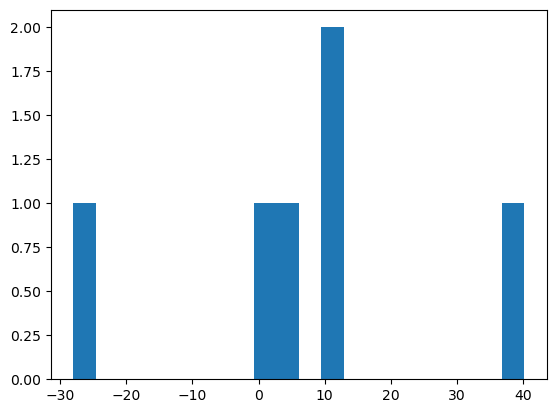

In [10]:
plt.hist(arr,bins=20)